<a href="https://colab.research.google.com/github/JaquelinedeJesus/Simulaci-n-2/blob/main/Movimiento%20Browniano%20con%20Deriva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Procesos derivados del Movimiento Browniano

**Alumna:** Espinoza Cano Jaqueline de Jesús

$B_t = W(t)$

1. Puente Browniano: $X_t = B_t - tB_1,\quad 0\le t\le 1$
2. MB con deriva: $X_t = \mu t + \sigma B_t,\quad t\ge 0,\ \sigma>0,\ \mu\in\mathbb{R}$

Para cada uno: **simular**, **hallar** $\mu(t)=E[X_t]$ y $\operatorname{cov}(X_t,X_s)$, y comprobar numéricamente.

**Ejercicio:** Encuentre la probabilidad de que el movimiento browniano con parámetro deriva, $\mu=0$.6, y varianza, $\sigma^2=0.25$, tome valores entre 1 y 3 al tiempo 4.

In [1]:
import random as r
import numpy as np
import matplotlib.pyplot as plt

## Movimiento Browniano discretizado

In [2]:
def brown(T, N):
    lista = [0.0]
    dt = T / N
    w_0 = 0.0
    for i in range(N):
        dw = r.gauss(0, 1)
        w_1 = w_0 + np.sqrt(dt) * dw
        lista.append(w_1)
        w_0 = w_1
    return lista

## **1. Puente Browniano**
$$X_t = B_t - tB_1,\qquad 0\le t\le 1$$
$X_0 = B_0 - 0\cdot B_1 = 0$, $\quad X_1 = B_1 - B_1 = 0$.

**Media**
$$\mu(t)=E[X_t] = E[B_t] - t\,E[B_1] = 0 - t\cdot 0 = 0$$

**Covarianza**
Como $\mu(t)=0$: $\operatorname{cov}(X_t,X_s)=E[X_tX_s]$. Usando $E[B_uB_v]=\min(u,v)$:
$$
\begin{aligned}
E[X_tX_s] &= E[(B_t - tB_1)(B_s - sB_1)]\\
&= E[B_tB_s] - s\,E[B_tB_1] - t\,E[B_1B_s] + ts\,E[B_1^2]\\
&= \min(t,s) - s\,\min(t,1) - t\,\min(1,s) + ts\cdot 1\\
&= \min(t,s) - st - ts + ts \qquad (t,s\le 1)\\
&= \min(t,s) - ts
\end{aligned}
$$
Con $s=t$, $\operatorname{Var}(X_t)=t-t^2=t(1-t)$, que vale $0$ en $t=0$ y $t=1$ (los extremos fijos) y es máxima en $t=1/2$ con valor $1/4$.

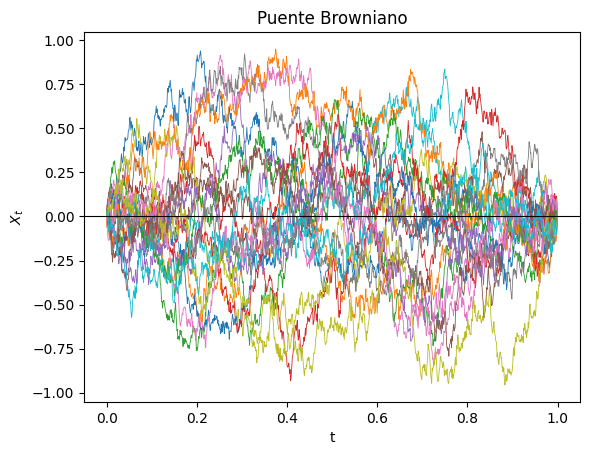

In [3]:
def puente(N):
    """
    Genera una trayectoria de un puente browniano con N pasos.

    Un puente browniano es un proceso estocástico que se comporta como
    un movimiento browniano estándar pero condicionado a terminar en 0
    en el instante final (t=1). Es decir, X(0) = X(1) = 0.

    Parámetros:
    -----------
    N : int
        Número de pasos (intervalos) de la discretización temporal.

    Retorna:
    --------
    t : np.ndarray
        Vector de tiempos en [0, 1] con N+1 puntos.
    X : list
        Valores de la trayectoria del puente browniano en cada instante t.
    """
    # Simula un movimiento browniano estándar B(t) con N pasos en [0,1].
    # 'brown' es una función auxiliar (no mostrada) que devuelve la lista
    # de valores del browniano en los N+1 instantes de tiempo.
    B = brown(1, N)

    # Discretización uniforme del intervalo [0, 1] en N+1 puntos.
    t = np.linspace(0, 1, N + 1)

    # Valor final del browniano simulado (B(1)).
    # Será el "desvío" que corregiremos para forzar el retorno a 0.
    B1 = B[-1]

    # Construcción del puente browniano mediante la transformación:
    #     X(t) = B(t) - t * B(1)
    # Esta fórmula garantiza que X(0) = 0 y X(1) = B(1) - 1*B(1) = 0,
    # "anclando" la trayectoria en ambos extremos.
    X = [B[i] - t[i] * B1 for i in range(N + 1)]

    return t, X


def trayectorias_puente(n, N=1000):
    # Genera y grafica cada una de las n trayectorias independientes.
    for i in range(n):
        t, X = puente(N)             # Simula una trayectoria del puente
        plt.plot(t, X, lw=0.6)       # La dibuja con línea fina (lw = linewidth)

    plt.axhline(0, color='k', lw=0.8)

    plt.title('Puente Browniano')
    plt.xlabel('t'); plt.ylabel('$X_t$')
    plt.show()
trayectorias_puente(20)

## Comprobación numérica de $\mu(t)$ y $\operatorname{cov}(X_t,X_s)$

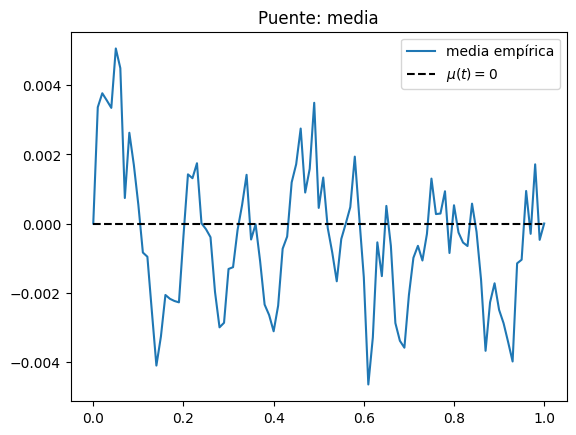

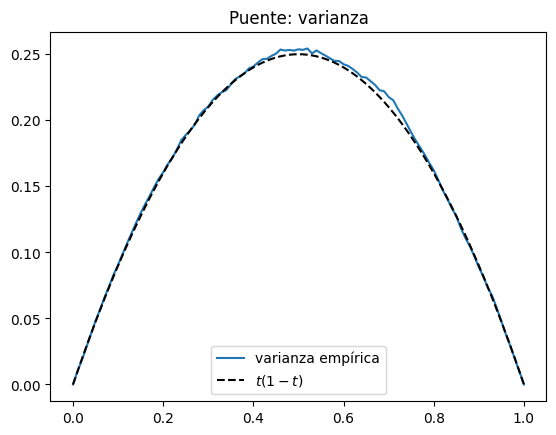

cov empírica  = 0.0947
min(s,t) - st = 0.0900


In [4]:
M, N = 5000, 100
t = np.linspace(0, 1, N + 1)
X = np.array([puente(N)[1] for _ in range(M)])

# Media
plt.plot(t, X.mean(axis=0), label='media empírica')
plt.plot(t, 0*t, 'k--', label='$\\mu(t)=0$')
plt.legend(); plt.title('Puente de la media'); plt.show()

# Varianza t(1-t)
plt.plot(t, X.var(axis=0), label='varianza empírica')
plt.plot(t, t*(1-t), 'k--', label='$t(1-t)$')
plt.legend(); plt.title('Puente de la varianza'); plt.show()

# Covarianza en un par (s, t)
i_s, i_t = 30, 70                     # s = 0.3, t = 0.7
s_, t_ = t[i_s], t[i_t]
cov_emp = np.mean((X[:, i_t] - X[:, i_t].mean()) * (X[:, i_s] - X[:, i_s].mean()))
print(f'cov empírica  = {cov_emp:.4f}')
print(f'min(s,t) - st = {min(s_, t_) - s_*t_:.4f}')

## **2. Movimiento Browniano con deriva**
$$X_t = \mu t + \sigma B_t,\qquad t\ge 0,\ \sigma>0,\ \mu\in\mathbb{R}$$

**Media**
$$E[X_t] = \mu t + \sigma E[B_t] = \mu t$$

**Covarianza**

$X_t - E[X_t] = \sigma B_t$, entonces
$$
\operatorname{cov}(X_t,X_s) = E[(\sigma B_t)(\sigma B_s)] = \sigma^2 E[B_tB_s] = \sigma^2\min(t,s)
$$
Comprobación: $\operatorname{Var}(X_t)=\sigma^2 t$, es decir $X_t\sim N(\mu t,\sigma^2 t)$. La deriva solo mueve la media; la covarianza es la del MB escalada por $\sigma^2$.

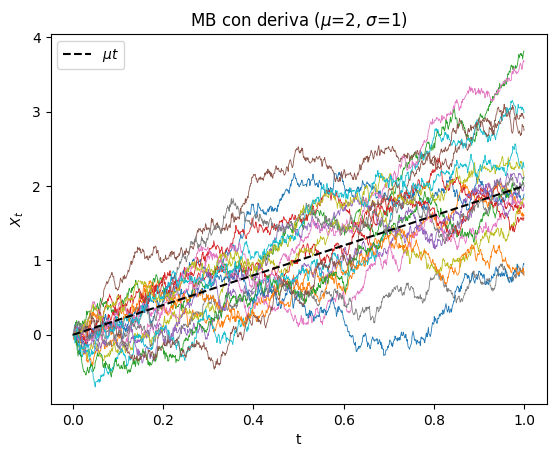

In [8]:
def deriva(mu, sigma, T, N):
    """
    Genera una trayectoria de un movimiento browniano con deriva (drift)
    sobre el intervalo [0, T] con N pasos de discretización.
    """
    B = brown(T, N)
    # Discretización uniforme del intervalo [0, T] en N+1 puntos.
    t = np.linspace(0, T, N + 1)

    # Construcción del MB con deriva mediante la fórmula:
    #     X(t) = mu * t + sigma * B(t)
    X = [mu * t[i] + sigma * B[i] for i in range(N + 1)]
    return t, X


def trayectorias_deriva(n, mu, sigma, T=1, N=1000):
    """
    Dibuja n trayectorias simuladas de un movimiento browniano con deriva,
    superponiendo además la tendencia determinista mu*t como referencia.
    """
    for i in range(n):
        t, X = deriva(mu, sigma, T, N)  # Simula una trayectoria
        plt.plot(t, X, lw=0.6)

    plt.plot(t, mu * t, 'k--', lw=1.5, label='$\\mu t$')
    plt.title(f'MB con deriva ($\\mu$={mu}, $\\sigma$={sigma})')  # ← paréntesis cerrado
    plt.xlabel('t'); plt.ylabel('$X_t$'); plt.legend()
    plt.show()


# Ejemplo de uso: 20 trayectorias con mu=2, sigma=1 en el intervalo [0, 1].
trayectorias_deriva(20, mu=2, sigma=1)

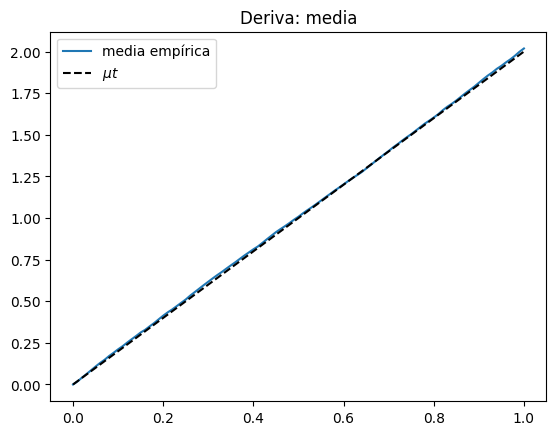

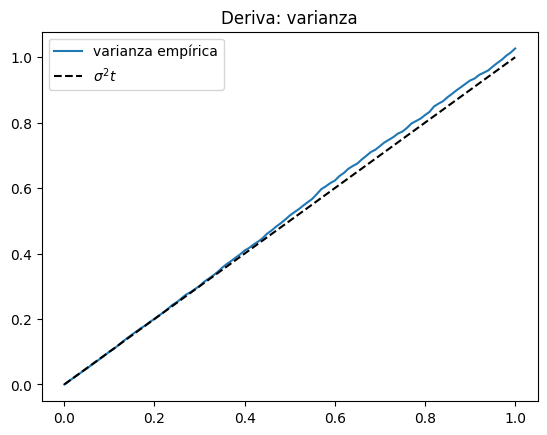

cov empírica      = 0.3104
sigma^2 min(s,t)  = 0.3000


In [9]:
# Parámetros del proceso y de la simulación Monte Carlo.
mu, sigma, T = 2, 1, 1
M, N = 5000, 100            # M = nº de trayectorias, N = nº de pasos
t = np.linspace(0, T, N + 1)

# Matriz M x (N+1): cada fila es una trayectoria simulada del MB con deriva.
X = np.array([deriva(mu, sigma, T, N)[1] for _ in range(M)])

# Verificación de la MEDIA: debe aproximarse a mu*t.
plt.plot(t, X.mean(axis=0), label='media empírica')
plt.plot(t, mu*t, 'k--', label='$\\mu t$')
plt.legend(); plt.title('Deriva: media'); plt.show()

# Verificación de la VARIANZA: debe aproximarse a sigma^2 * t.
plt.plot(t, X.var(axis=0), label='varianza empírica')
plt.plot(t, sigma**2 * t, 'k--', label='$\\sigma^2 t$')
plt.legend(); plt.title('Deriva: varianza'); plt.show()

# Verificación de la COVARIANZA en dos instantes s < t:
# teóricamente Cov(X_s, X_t) = sigma^2 * min(s, t).
i_s, i_t = 30, 70
s_, t_ = t[i_s], t[i_t]
cov_emp = np.mean((X[:, i_t] - X[:, i_t].mean()) * (X[:, i_s] - X[:, i_s].mean()))
print(f'cov empírica      = {cov_emp:.4f}')
print(f'sigma^2 min(s,t)  = {sigma**2 * min(s_, t_):.4f}')